#Classification

In [1]:
#Importation des bibliothèques nécessaires
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
#Lecture et affichage du dataset
df = pd.read_csv('/content/drive/MyDrive/DM_Master_SDSI/Classification_app/Raisin_Dataset.csv')
df

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen
...,...,...,...,...,...,...,...,...
895,83248,430.077308,247.838695,0.817263,85839,0.668793,1129.072,Besni
896,87350,440.735698,259.293149,0.808629,90899,0.636476,1214.252,Besni
897,99657,431.706981,298.837323,0.721684,106264,0.741099,1292.828,Besni
898,93523,476.344094,254.176054,0.845739,97653,0.658798,1258.548,Besni


In [3]:
df.describe()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
count,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000
mean,87804.127778,430.929950,254.488133,0.781542,91186.090000,0.699508,1165.906636
std,39002.111390,116.035121,49.988902,0.090318,40769.290132,0.053468,273.764315
min,25387.000000,225.629541,143.710872,0.348730,26139.000000,0.379856,619.074000
25%,59348.000000,345.442898,219.111126,0.741766,61513.250000,0.670869,966.410750
50%,78902.000000,407.803951,247.848409,0.798846,81651.000000,0.707367,1119.509000
75%,105028.250000,494.187014,279.888575,0.842571,108375.750000,0.734991,1308.389750
max,235047.000000,997.291941,492.275279,0.962124,278217.000000,0.835455,2697.753000


In [4]:
df['Class'].value_counts()

,count
Class,
Kecimen,450
Besni,450


In [5]:
#Pré-traitement :
#Encodage (Besni:0, Kecimen:1)
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['Class'] = le.fit_transform(df['Class'])

#Fonction de normalisation(Scalling)
from sklearn import preprocessing
def normalize(data):
  min_max_scaler = preprocessing.MinMaxScaler()
  return min_max_scaler.fit_transform(data)

df['Class'].value_counts()

,count
Class,
1,450
0,450


In [6]:
#Séparation des données : Train(80%)/Test(20%)
from sklearn.model_selection import train_test_split
y=df['Class']
x=normalize(df.drop('Class',axis=1))
#x=df.drop('class',axis=1)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)

In [22]:
x[480]

array([0.53477535, 0.49047988, 0.4257038 , 0.85851508, 0.45890161,
       0.4865375 , 0.43812248])

In [21]:
y[480]

np.int64(0)

In [11]:
#Procédure d'entrainement, test, et évaluation des modèles

from sklearn.metrics import f1_score, confusion_matrix, classification_report, matthews_corrcoef
from sklearn.model_selection import learning_curve
def train_test_eval(model):
    model.fit(x_train, y_train)
    ypred = model.predict(x_test)
    print('Matrice de confusion : \n', confusion_matrix(y_test, ypred))
    print(classification_report(y_test, ypred))
    #print('F1 : ', f1_score(y_test, ypred))
    print('MCC : ', matthews_corrcoef(y_test, ypred))
    N, train_score, val_score = learning_curve(model, x_train, y_train, cv=5, scoring='matthews_corrcoef')
    plt.figure(figsize=(6, 6))
    #plt.plot(N, train_score.mean(axis=1), label='train score')
    plt.plot(N, val_score.mean(axis=1), label='validation score')
    plt.legend()
    plt.show()


*************************************************************
DecisionTree
*************************************************************
Matrice de confusion : 
 [[80 17]
 [13 70]]
              precision    recall  f1-score   support

           0       0.86      0.82      0.84        97
           1       0.80      0.84      0.82        83

    accuracy                           0.83       180
   macro avg       0.83      0.83      0.83       180
weighted avg       0.83      0.83      0.83       180

MCC :  0.6664622122426178


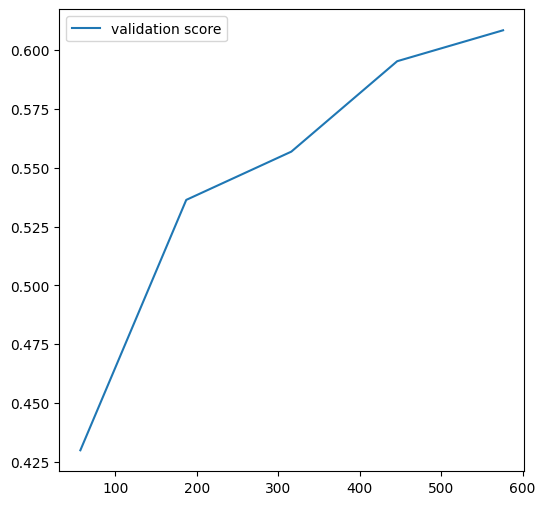

*************************************************************
SVM
*************************************************************
Matrice de confusion : 
 [[84 13]
 [ 6 77]]
              precision    recall  f1-score   support

           0       0.93      0.87      0.90        97
           1       0.86      0.93      0.89        83

    accuracy                           0.89       180
   macro avg       0.89      0.90      0.89       180
weighted avg       0.90      0.89      0.89       180

MCC :  0.7912859151897575


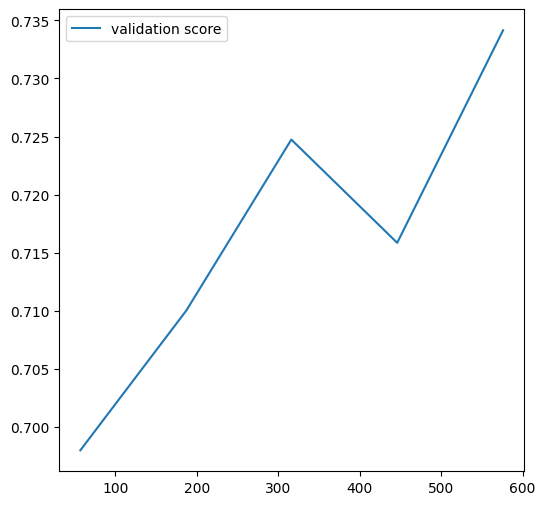

*************************************************************
KNN
*************************************************************
Matrice de confusion : 
 [[82 15]
 [13 70]]
              precision    recall  f1-score   support

           0       0.86      0.85      0.85        97
           1       0.82      0.84      0.83        83

    accuracy                           0.84       180
   macro avg       0.84      0.84      0.84       180
weighted avg       0.84      0.84      0.84       180

MCC :  0.6877100509777067


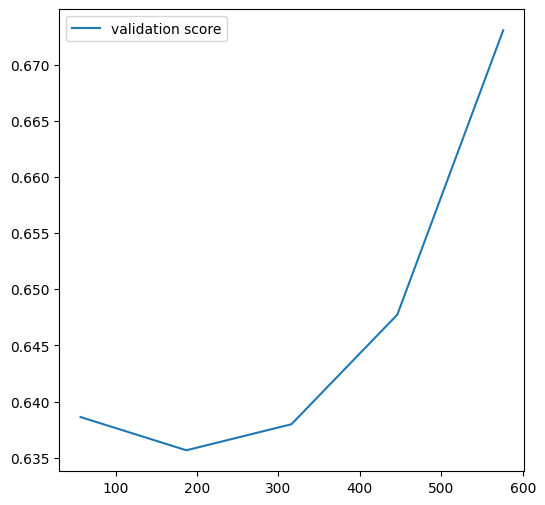

In [12]:
#Modélisation
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

DT = DecisionTreeClassifier(random_state=0)
SVM = SVC(random_state=0)
KNN = KNeighborsClassifier(n_neighbors=3)

#Liste des modèles
dict_of_models = {'DecisionTree': DT,
                  'SVM': SVM,
                  'KNN': KNN
                 }

for name, model in dict_of_models.items():
  print('*************************************************************')
  print(name)
  print('*************************************************************')
  train_test_eval(model)

#SVM.fit(x_train, y_train)
#ypred = SVM.predict(x_test)
#print('Matrice de confusion : \n', confusion_matrix(y_test, ypred))

In [13]:
#Optimisation du modèle sélectionné : SVM
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
SVM.get_params()

{'C': 1.0,
 'break_ties': False,
 'cache_size': 200,
 'class_weight': None,
 'coef0': 0.0,
 'decision_function_shape': 'ovr',
 'degree': 3,
 'gamma': 'scale',
 'kernel': 'rbf',
 'max_iter': -1,
 'probability': False,
 'random_state': 0,
 'shrinking': True,
 'tol': 0.001,
 'verbose': False}

{'tol': 0.0001, 'gamma': 1, 'degree': 4, 'C': 10}
              precision    recall  f1-score   support

           0       0.93      0.88      0.90        97
           1       0.87      0.93      0.90        83

    accuracy                           0.90       180
   macro avg       0.90      0.90      0.90       180
weighted avg       0.90      0.90      0.90       180

MCC :  0.8016134476923238


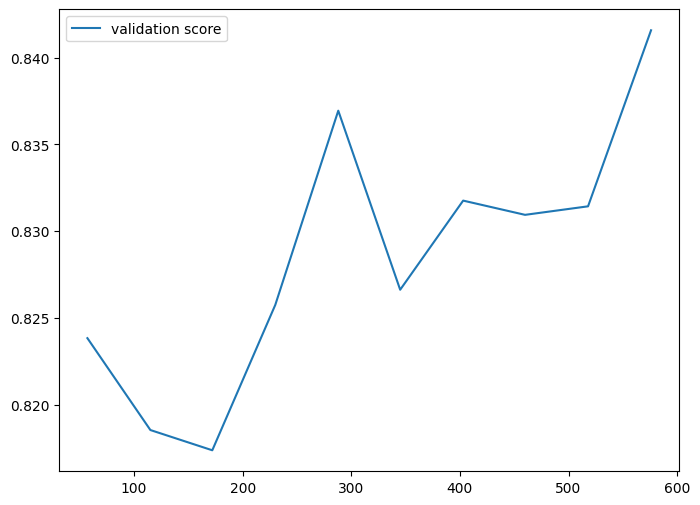

In [15]:
hyper_params = {'gamma':[1, 1e-1, 1e-2, 1e-3, 1e-4, 0.0005],
                'C':[1, 10, 100, 1000, 3000],
                'tol':[1e-3, 1e-4],
               'degree':[1, 2, 3, 4, 5]}
#grid = GridSearchCV(SVM, hyper_params, scoring='f1_weighted', cv=5)
grid = RandomizedSearchCV(SVM, hyper_params, scoring='f1_weighted', cv=5,  n_iter=100)

grid.fit(x_train, y_train)
print(grid.best_params_)

#Evaluation du modèle optimisé
y_pred = grid.predict(x_test)
print(classification_report(y_test, y_pred))
#print('F1 : ', f1_score(y_test, y_pred))
print('MCC : ', matthews_corrcoef(y_test, y_pred))
N, train_score, val_score = learning_curve(model, x_train, y_train, scoring='f1', train_sizes=np.linspace(0.1, 1, 10))

plt.figure(figsize=(8, 6))
#plt.plot(N, train_score.mean(axis=1), label='train score')
plt.plot(N, val_score.mean(axis=1), label='validation score')
plt.legend()
plt.show()

In [16]:
#Enregistrer le modèle final
import pickle
pickle.dump(grid, open('/content/drive/MyDrive/DM_Master_SDSI/Classification_app/model.pkl', 'wb'))